# Laboratorio Dry Bean - Sprint 2: modelado y evaluación

**Proyecto:** Clasificación de variedades de frijol seco (Dry Bean Dataset, UCI 602)
**Equipo:** Jacobo Unzueta y Rommel Prieto - Maestría en IA y Ciencia de Datos, Universidad Autónoma de Occidente
**Metodologías:** CRISP-DM · TDSP · Scrum ML
**Sprint 2:** PB-03 (baseline), PB-04 (Random Forest), PB-05 (comparación de métricas)

## Objetivo del sprint

Entrenar un baseline, un modelo alternativo y un tercer modelo, compararlos con
métricas adecuadas al desbalance y decidir cuál pasa a despliegue usando
validación cruzada, no una única partición de test.

**Requisito:** haber ejecutado antes `python -m src.sprint1` (genera `data/processed/`).


## 0. Configuración e importaciones

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import pandas as pd
from IPython.display import Image, display

from src import config, models, prepare
from src.eda import dataframe_to_markdown

pd.set_option("display.width", 120)
print("Raíz del proyecto:", config.PROJECT_ROOT)
print("Semilla:", config.RANDOM_STATE, "| folds CV:", models.CV_FOLDS)

Raíz del proyecto: C:\Users\Jacobo\Documents\GestionProyectosIA\laboratorio_drybean_ml
Semilla: 42 | folds CV: 5


## 1. Cargar los conjuntos procesados del Sprint 1

Mismo split estratificado para los tres modelos: la comparación es justa y
reproducible.

In [2]:
X_train, X_test, y_train, y_test = prepare.load_processed_data()
print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Clases: {sorted(y_train.unique())}")

Train: (10834, 16) | Test: (2709, 16)
Clases: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


## 2. Baseline: regresión logística (PB-03)

`StandardScaler` + `LogisticRegression(max_iter=1000)`. El escalamiento vive dentro
del pipeline, así que se ajusta solo con train (sin fuga de información).

In [3]:
baseline, baseline_seconds = models.train_model(
    models.build_baseline_pipeline(), X_train, y_train
)
baseline_result = models.evaluate_model(
    baseline, X_test, y_test, models.BASELINE_NAME, baseline_seconds
)
print(f"Tiempo: {baseline_seconds:.2f}s")
print(f"Accuracy: {baseline_result['metrics']['accuracy']:.4f}")
print(f"F1 macro: {baseline_result['metrics']['f1_macro']:.4f}")

Tiempo: 0.10s
Accuracy: 0.9195
F1 macro: 0.9306


**Pregunta del laboratorio:** ¿por qué F1 macro puede ser más informativo que
accuracy cuando las clases no están balanceadas?

**Respuesta:** con 7 clases y una relación 6,79:1, la clase mayoritaria bien
predicha puede esconder fallos en `BOMBAY` o `BARBUNYA`. F1 macro promedia el F1
de cada clase con el mismo peso, así que castiga al modelo que abandona clases
minoritarias.

## 3. Modelo alternativo: Random Forest (PB-04)

200 árboles con `class_weight="balanced"`. Los árboles no necesitan escalamiento.

In [4]:
forest, forest_seconds = models.train_model(
    models.build_forest_model(), X_train, y_train
)
forest_result = models.evaluate_model(
    forest, X_test, y_test, models.FOREST_NAME, forest_seconds
)
print(f"Tiempo: {forest_seconds:.2f}s")
print(f"Accuracy: {forest_result['metrics']['accuracy']:.4f}")
print(f"F1 macro: {forest_result['metrics']['f1_macro']:.4f}")

Tiempo: 0.36s
Accuracy: 0.9195
F1 macro: 0.9310


## 4. Tercer modelo: HistGradientBoosting

Gradient boosting sobre histogramas. La regularización L2 se eligió con validación
cruzada: `l2_regularization=1.0` dio el mejor F1 macro medio (0,9429) frente al
modelo por defecto (0,9419) y a `max_leaf_nodes=63` (0,9427).

In [5]:
hgb, hgb_seconds = models.train_model(
    models.build_hgb_model(), X_train, y_train
)
hgb_result = models.evaluate_model(
    hgb, X_test, y_test, models.HGB_NAME, hgb_seconds
)
print(f"Tiempo: {hgb_seconds:.2f}s")
print(f"Accuracy: {hgb_result['metrics']['accuracy']:.4f}")
print(f"F1 macro: {hgb_result['metrics']['f1_macro']:.4f}")

Tiempo: 0.42s
Accuracy: 0.9195
F1 macro: 0.9315


## 5. Validación cruzada 5-fold (protocolo de decisión)

El conjunto de prueba tiene 2.709 filas: diferencias de milésimas entre modelos
son ruido. Por eso la **decisión** se toma con F1 macro medio de 5-fold sobre
train, y el test queda como verificación honesta.

In [6]:
builders = {
    models.BASELINE_NAME: models.build_baseline_pipeline,
    models.FOREST_NAME: models.build_forest_model,
    models.HGB_NAME: models.build_hgb_model,
}

cv_results = {}
for name, builder in builders.items():
    cv_results[name] = models.cross_validate_model(builder(), X_train, y_train)
    print(f"{name:22} F1 macro CV = {cv_results[name]['mean']:.4f} "
          f"(±{cv_results[name]['std']:.4f})")

Logistic Regression    F1 macro CV = 0.9360 (±0.0031)


Random Forest          F1 macro CV = 0.9352 (±0.0016)


HistGradientBoosting   F1 macro CV = 0.9429 (±0.0032)


In [7]:
cv_table = pd.DataFrame(
    {
        "F1 macro medio": [cv_results[name]["mean"] for name in builders],
        "Desv. estándar": [cv_results[name]["std"] for name in builders],
        "Folds": [" · ".join(f"{s:.4f}" for s in cv_results[name]["scores"]) for name in builders],
    },
    index=list(builders),
)
cv_table.index.name = "modelo"
print(dataframe_to_markdown(cv_table.round(4), float_format="{:.4f}", adaptive=False))

| modelo | F1 macro medio | Desv. estándar | Folds |
|---|---|---|---|
| Logistic Regression | 0.9360 | 0.0031 | 0.9378 · 0.9337 · 0.9336 · 0.9336 · 0.9412 |
| Random Forest | 0.9352 | 0.0016 | 0.9373 · 0.9337 · 0.9344 · 0.9337 · 0.9368 |
| HistGradientBoosting | 0.9429 | 0.0032 | 0.9430 · 0.9457 · 0.9429 · 0.9370 · 0.9459 |


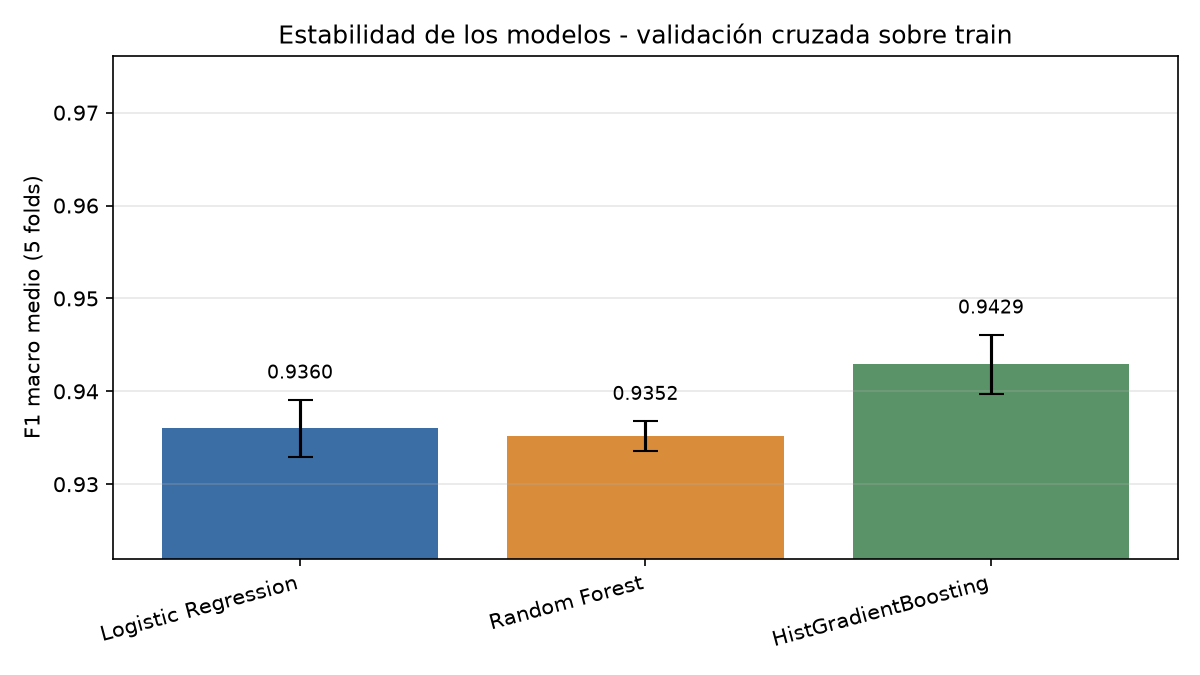

In [8]:
display(Image(filename=str(config.SPRINT2_FIGURES_DIR / "comparacion_cv.png")))

## 6. Comparación de métricas (PB-05)

In [9]:
results = {
    models.BASELINE_NAME: baseline_result,
    models.FOREST_NAME: forest_result,
    models.HGB_NAME: hgb_result,
}
comparison = models.build_comparison_table(results, cv_results)
print(dataframe_to_markdown(comparison.reset_index().round(4), float_format="{:.4f}", adaptive=False))

|  | modelo | accuracy | f1_macro | f1_weighted | balanced_accuracy | precision_macro | recall_macro | train_seconds | cv_f1_macro_mean | cv_f1_macro_std |
|---|---|---|---|---|---|---|---|---|---|---|
| 0 | Logistic Regression | 0.9195 | 0.9306 | 0.9197 | 0.9303 | 0.9311 | 0.9303 | 0.1040 | 0.9360 | 0.0031 |
| 1 | Random Forest | 0.9195 | 0.9310 | 0.9195 | 0.9310 | 0.9312 | 0.9310 | 0.3620 | 0.9352 | 0.0016 |
| 2 | HistGradientBoosting | 0.9195 | 0.9315 | 0.9195 | 0.9307 | 0.9323 | 0.9307 | 0.4180 | 0.9429 | 0.0032 |


Los tres modelos coinciden en el 94.13% de las predicciones


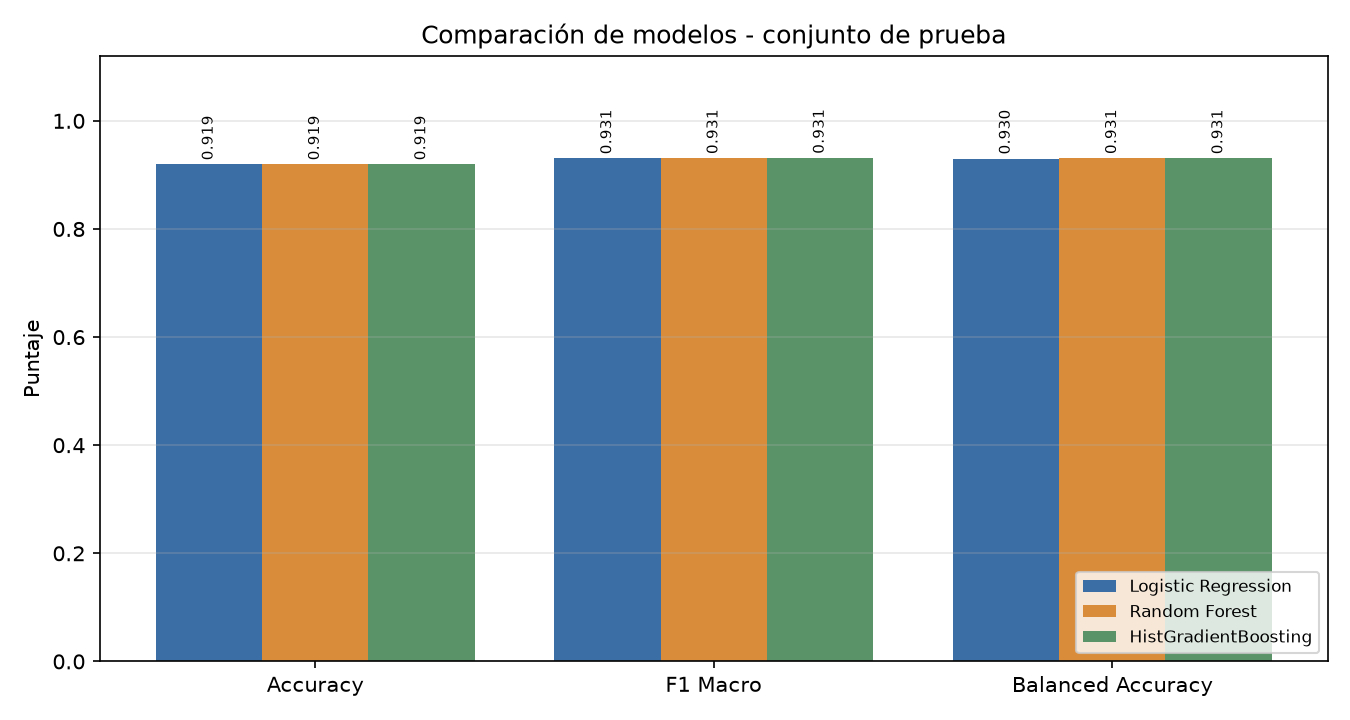

In [10]:
agreement = (
    (baseline_result["y_pred"] == forest_result["y_pred"])
    & (forest_result["y_pred"] == hgb_result["y_pred"])
).mean()
print(f"Los tres modelos coinciden en el {agreement:.2%} de las predicciones")
display(Image(filename=str(config.SPRINT2_FIGURES_DIR / "comparacion_modelos.png")))

## 7. Matrices de confusión

Muestran **dónde** falla cada modelo, no solo cuánto.

confusion_histgradientboosting.png


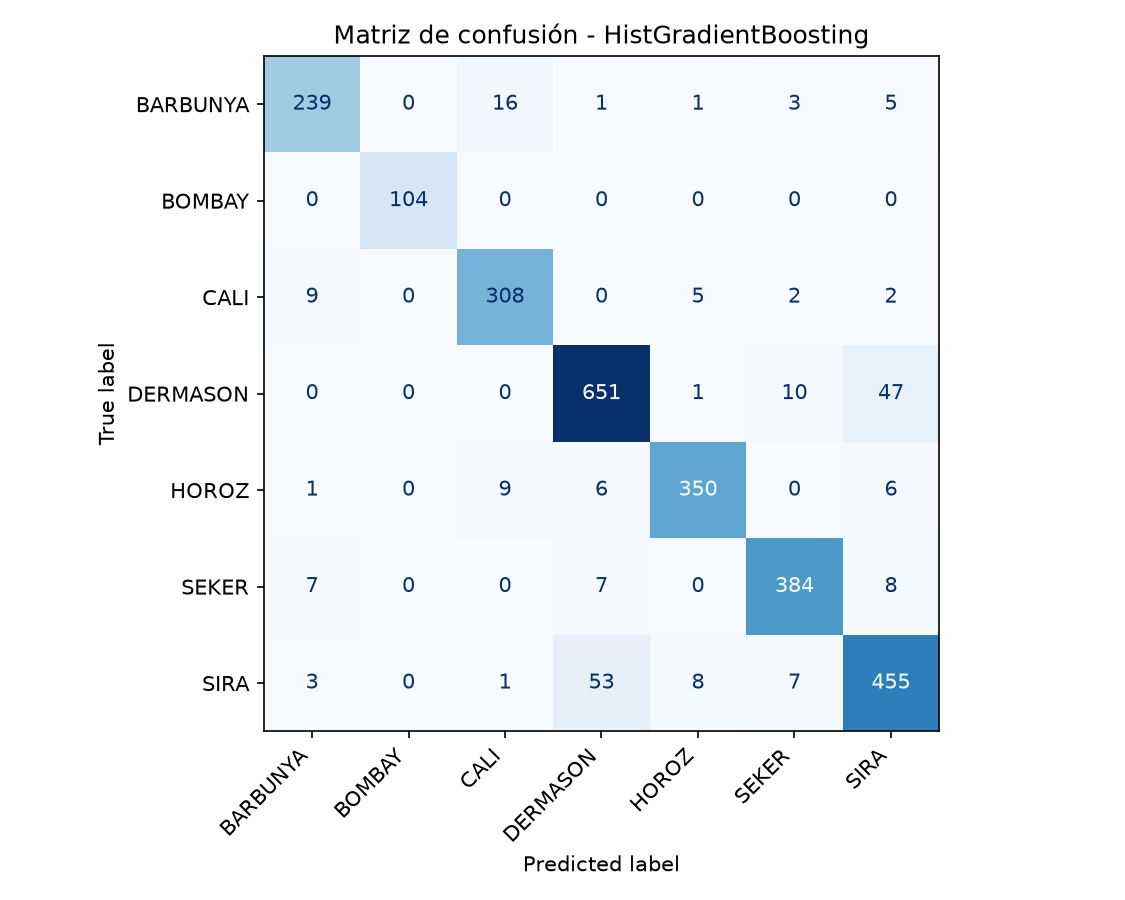

confusion_random_forest.png


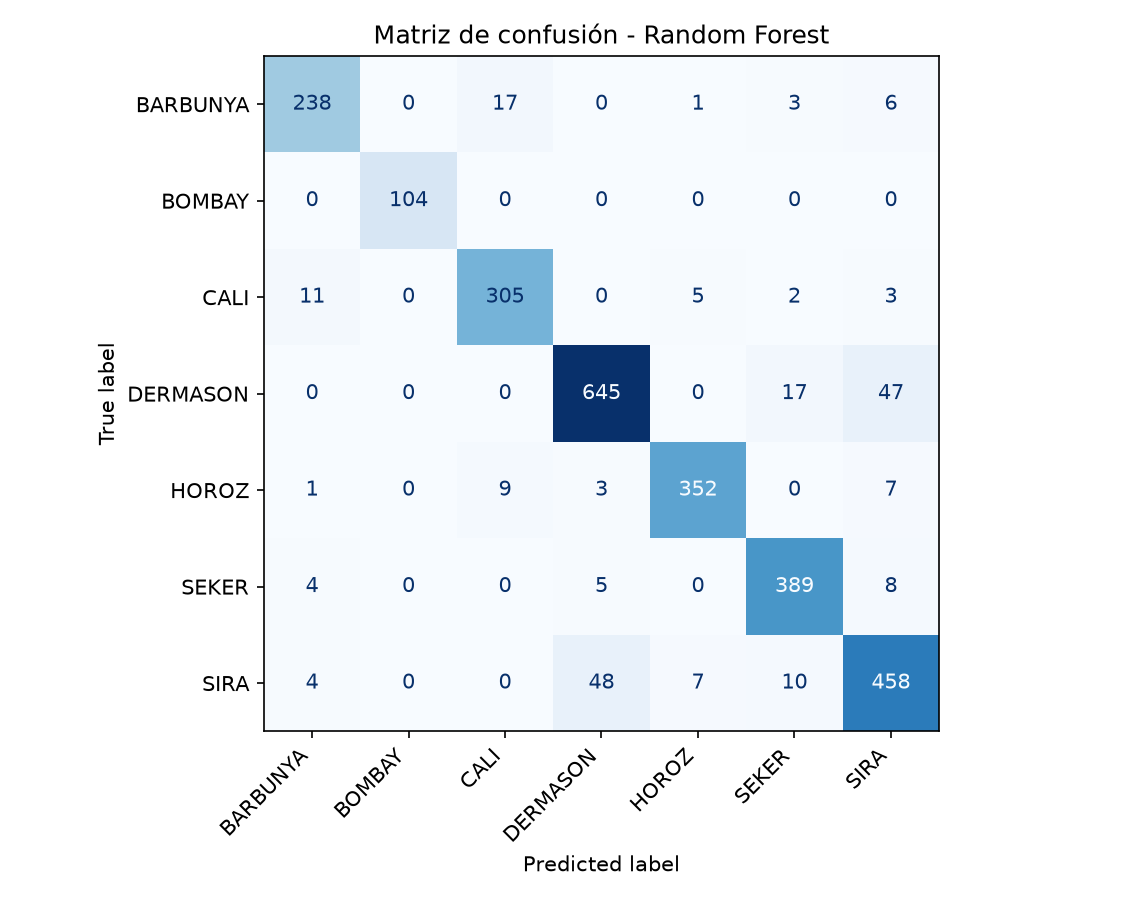

confusion_logistic_regression.png


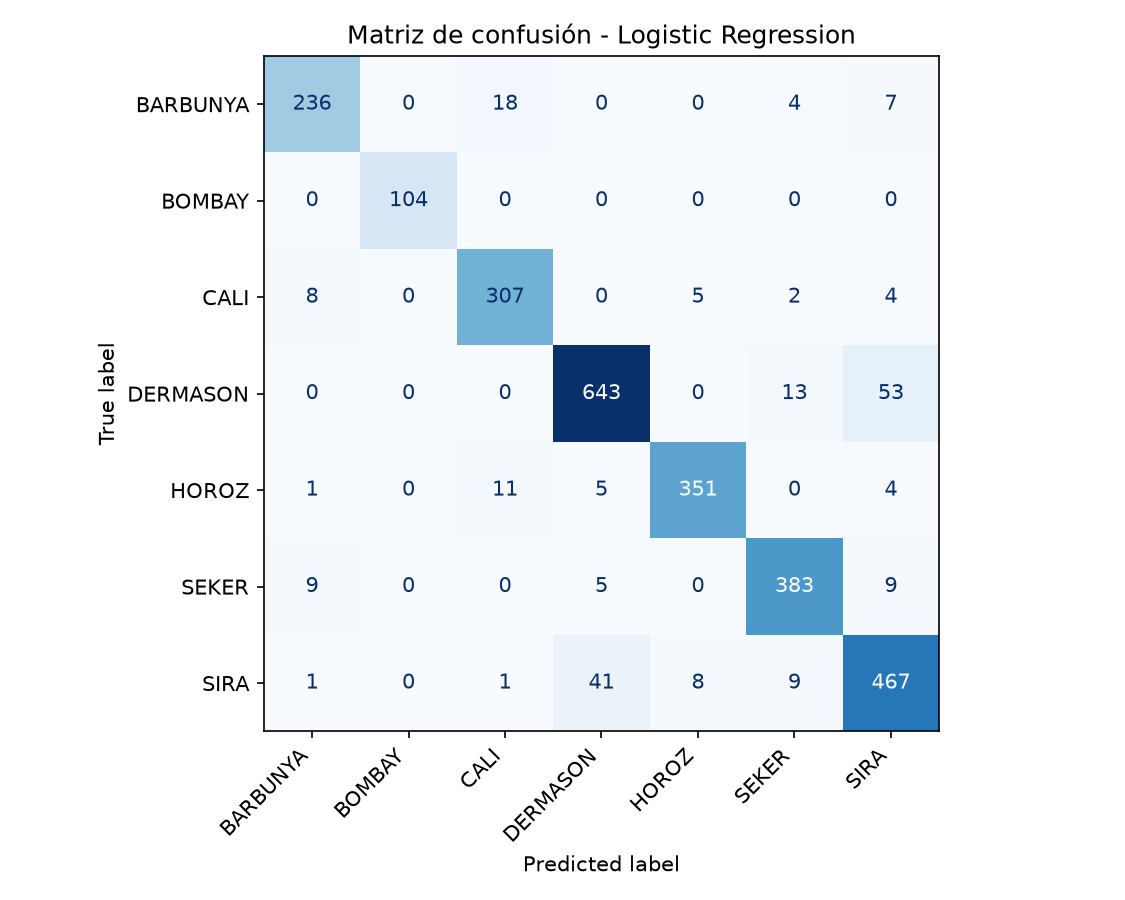

In [11]:
for figura in ["confusion_histgradientboosting.png", "confusion_random_forest.png", "confusion_logistic_regression.png"]:
    print(figura)
    display(Image(filename=str(config.SPRINT2_FIGURES_DIR / figura)))

In [12]:
from src import evaluate

for nombre, resultado in results.items():
    print(f"\n{nombre}")
    for par in evaluate.top_confusions(resultado, n=3):
        print(
            f"  {par['real']:>9} -> {par['predicho']:<9} "
            f"{par['casos']:>4} casos ({par['tasa']:.1%} de la clase real)"
        )


Logistic Regression
   DERMASON -> SIRA        53 casos (7.5% de la clase real)
       SIRA -> DERMASON    41 casos (7.8% de la clase real)
   BARBUNYA -> CALI        18 casos (6.8% de la clase real)

Random Forest
       SIRA -> DERMASON    48 casos (9.1% de la clase real)
   DERMASON -> SIRA        47 casos (6.6% de la clase real)
   BARBUNYA -> CALI        17 casos (6.4% de la clase real)

HistGradientBoosting
       SIRA -> DERMASON    53 casos (10.1% de la clase real)
   DERMASON -> SIRA        47 casos (6.6% de la clase real)
   BARBUNYA -> CALI        16 casos (6.0% de la clase real)


**Pregunta del laboratorio:** ¿qué clases se confunden más entre sí?

`SIRA` y `DERMASON` se confunden en ambos sentidos en los tres modelos (variedades
de tamaño y forma parecidos). `BOMBAY`, la más pequeña y minoritaria, sale perfecta:
sus medidas geométricas son claramente distintas.

## 8. Importancia de variables

Se calcula con el Random Forest (el gradient boosting no expone importancias por
impureza). **No prueba causalidad.**

| # | variable | importancia |
|---|---|---|
| 1 | Perimeter | 0.109 |
| 2 | ShapeFactor1 | 0.102 |
| 3 | Compactness | 0.095 |
| 4 | ShapeFactor3 | 0.094 |
| 5 | MinorAxisLength | 0.093 |
| 6 | EquivDiameter | 0.067 |
| 7 | Roundness | 0.062 |
| 8 | AspectRatio | 0.060 |
| 9 | Eccentricity | 0.059 |
| 10 | Area | 0.058 |


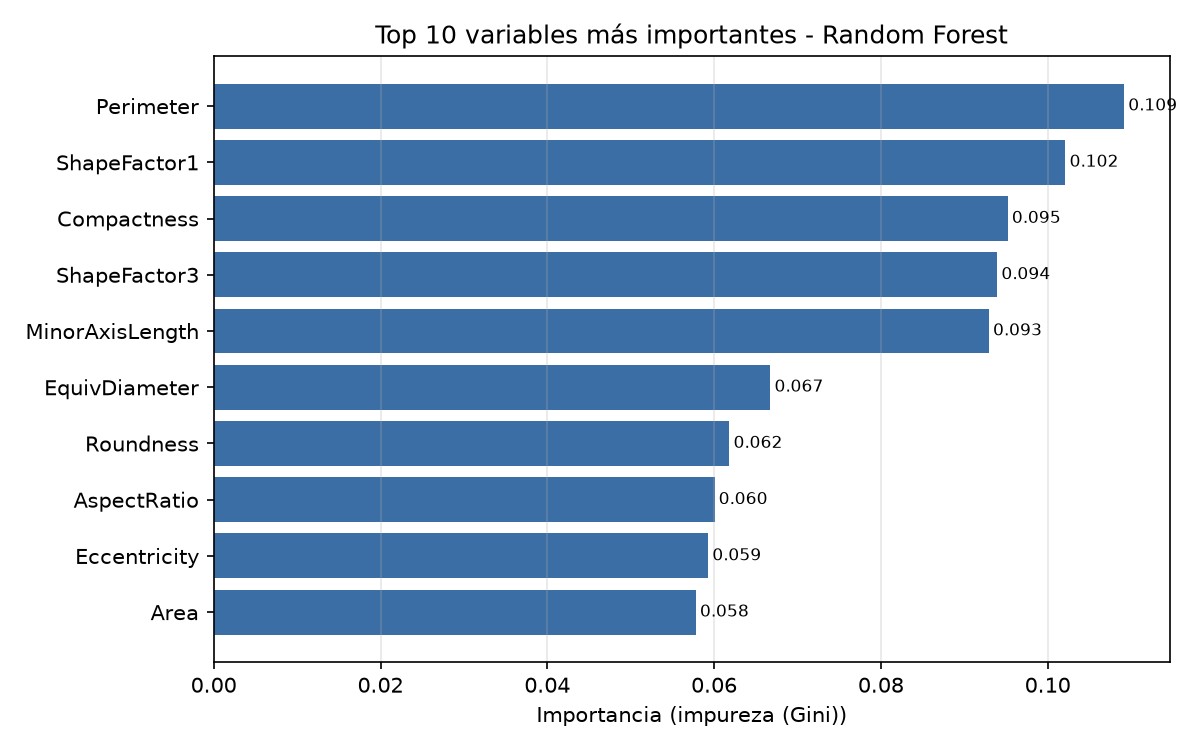

In [13]:
importance = models.feature_importance(forest, list(X_train.columns))
top10 = importance.head(10).copy()
top10.index = range(1, len(top10) + 1)
top10.index.name = "#"
print(dataframe_to_markdown(top10))
display(Image(filename=str(config.SPRINT2_FIGURES_DIR / "importancia_variables.png")))

## 9. Decisión CRISP-DM: qué modelo pasa a despliegue

Criterio: priorizar el F1 macro medio de la validación cruzada; si la diferencia
es menor que 0,005, preferir el modelo más simple y rápido.

In [14]:
selection = models.select_best_model(comparison)
print("Ranking CV:", selection["ranking"])
print("Ranking test:", selection["test_f1_macro_ranking"])
print("Modelo seleccionado:", selection["selected"])
print("Justificación:", selection["rationale"])

Ranking CV: {'HistGradientBoosting': 0.9429, 'Logistic Regression': 0.936, 'Random Forest': 0.9352}
Ranking test: {'HistGradientBoosting': 0.9315, 'Logistic Regression': 0.9306, 'Random Forest': 0.931}
Modelo seleccionado: HistGradientBoosting
Justificación: HistGradientBoosting supera a Logistic Regression por 0.0069 de cv_f1_macro_mean, por lo que pasa a la fase de despliegue.


In [15]:
metadata = json.loads(
    config.FINAL_MODEL_PATH.with_suffix(".metadata.json").read_text(encoding="utf-8")
)
print("Artefacto:", config.FINAL_MODEL_PATH.name)
print(json.dumps(
    {k: metadata[k] for k in ["selected_model", "model_type", "metrics", "train_rows", "test_rows", "sklearn_version"]},
    indent=2,
    ensure_ascii=False,
))

Artefacto: modelo_final_drybean.joblib
{
  "selected_model": "HistGradientBoosting",
  "model_type": "HistGradientBoostingClassifier",
  "metrics": {
    "accuracy": 0.9195275009228497,
    "f1_macro": 0.9314609520761044,
    "cv_f1_macro_mean": 0.9428986627760587,
    "cv_f1_macro_std": 0.0032057239012787176
  },
  "train_rows": 10834,
  "test_rows": 2709,
  "sklearn_version": "1.9.1"
}


## 10. Conclusiones del Sprint 2

1. Los tres modelos rondan el 91,95% de accuracy: el problema está bien planteado,
   pero el techo está en las variables, no en el algoritmo.
2. La validación cruzada ordena con más estabilidad que el hold-out y es la base
   de la decisión: HistGradientBoosting gana en las 5 particiones.
3. `SIRA` ↔ `DERMASON` es la confusión dominante; `BOMBAY` se separa sin errores.
4. El modelo seleccionado se guarda en `outputs/models/` con metadatos de
   trazabilidad (tipo de modelo, métricas, features, clases, versión de sklearn).
5. Sprint 3: cargar el `.joblib`, función de predicción reutilizable, demo y
   documentación final del proyecto.
